# PlantCV Analysis of MS (aka multispec) sideview (SV) images from experiment PC001 in the Bellwether Phenotyping Facility

Made by: Katie Murphy

Updated: September 15, 2026

We will work through the notebook interactively with one (or a few) test images. After you are happy with the workflow, you will run the analysis over the images in batch (aka parallel). You will not analyze the outputs from this workflow, it is just to set up your script. 

## Step 1: Import Packages

First, import the necessary package. If you get an error here, make sure your kernel (upper right) is set to PlantCV, and that you have PlantCV installed. 

In [1]:
# Use the interactive matplotlib backend so plots can be zoomed/panned in the notebook
%matplotlib inline
import numpy as np
# Import the main PlantCV module (all image processing functions live here)
from plantcv import plantcv as pcv
# WorkflowInputs bundles your image path(s) and output settings into one object
from plantcv.parallel import WorkflowInputs, workflow_inputs, JupyterConfig
import os

## Step 2: Set Up Workflow Inputs

Next, import one image. The image needs to be in the same location that you are working on; for example, if this notebook is on your computer, the image must be on your computer. You cannot reach images from the server if this notebook is on your computer Remember, always keep your raw images separate from your newly processed images! You will need to change the path to your image, and also if you want specific output folders and directories. 

In [2]:
# @ignore
# Input/output options
args = WorkflowInputs(
    images=["/data/datascience/users/jsumner/pc001/murphy/MC017YC156464/2026-08-22/snapshot2761500/MS455_SV_BP0_0_h0_g170_e3000_v500_5321000_0.png"],  # path(s) to your image(s); pointing at one MS image pulls in the rest of its multispectral set
    names="image1",              # variable name(s) to assign to each image, referenced later as args.image
    result="example_results_oneimage_file.csv",  # filename where extracted trait measurements will be saved
    outdir=".",                 # output directory for results/images ("." = current folder)
    writeimg=False,             # set to True if you want PlantCV to save output images to disk
    debug="plot"                # "plot" displays each processing step inline; use "print" to save step images to disk, or None to turn off debug images
    )

## Optional Step 2.5: Prepping for Parallelization

There are two ways to parallelize a workflow in PlantCV. The first is to make a `WorkflowConfig` object that points to an executable python script (`.py` file) and save the config to a json file. It can then be run with `plantcv-run-workflow --config config_filename.json`.
The second way is new in version 5 of PlantCV and works from jupyter using the `plantcv.parallel.JupyterConfig` class. The `JupyterConfig` object can be edited just like you would a `WorkflowConfig` object but it comes with methods to inspect your dataset before you run and to run the parallel workflow treating your jupyter session as the "head node".

Additionally there are several ways to do most subsetting when you are trying to filter images. The following three calls to `JupyterConfig` will all find the same images as shown with the output of `inspect_dataset`.

In [3]:
jupcon = JupyterConfig()
jupcon.verbose = False
jupcon.checkpoint = False
jupcon.input_dir = "/data/datascience/users/jsumner/pc001/murphy/" # path relative to your notebook
jupcon.metadata_regex = {"basename": "VIS_TV.*"} # doing it this way we'd just work from the directory level. it will list out VIS in the outputs file, but it is really analyzing the corresponding MS images
# aka, we'd use the directory to read MS from.
summary, full_meta = jupcon.inspect_dataset()
# Take as many workers as seem reasonable.
jupcon.cluster_config["n_workers"] = 10
jupcon.cluster = "HTCondorCluster"
jupcon.cluster_config["log_directory"] = "./logs"
jupcon.cluster_config["local_directory"] = "$_CONDOR_SCRATCH_DIR"
jupcon.cluster_config["job_extra_directives"] = {"getenv": "true"}
#jupcon.cluster_config["submit_command_extra"] = ["request_memory = 2GB"]
jupcon.cluster_config["memory"] = "10GB"
summary

Run will not be verbose


,filepath,timestamp,snapshot,local_time,camera_label,tiled_image_id,raw_image_oid,rotate_flip_type,dataformat,width,...,lifter,gain,exposure,dir1,dir2,dir3,basename,velocity,rotation,extension
status,,,,,,,,,,,,,,,,,,,,,
Kept,756 (...),756 (...),756 (...),756 (...),1 (VIS_TV_z1_h0_g370_e1800),756 (...),756 (...),1 (0),1 (10),1 (4128),...,1 (0),1 (370),1 (1800),108 (...),7 (...),756 (...),756 (...),0,0,1 (.png)
Removed by config.metadata_regex,6804 (...),1404 (...),1404 (...),1404 (...),17 (...),6804 (...),6804 (...),"2 (2, 0)","2 (0, 10)","2 (4096, 4128)",...,"2 (0, 1)","2 (170, 370)",12 (...),108 (...),13 (...),1404 (...),6804 (...),1 (500),"2 (0, 90)",1 (.png)


In [4]:
# when you are ready to run in parallel save the notebook, restart the kernel (just to be safe)
# and run to this cell with `jupcon.run()` and `args = workflow_inputs()` uncommmented

#jupcon.run()

Starting run 2026-10-30_13-23-01

Setting job_script_prologue to fetch active environment:
 ['source /data/apps/miniforge3/bin/activate', 'conda activate plantcv']
Reading image metadata...
Building job list... 
Processing images... 
/data/apps/miniforge3/envs/plantcv/lib/python3.13/site-packages/distributed/node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 21063 instead
  warnings.warn(
2026-10-30 14:01:24,209 - distributed.batched - INFO - Batched Comm Closed <TCP (closed)  local=tcp://10.5.1.92:14899 remote=tcp://10.5.1.92:32362>
Traceback (most recent call last):
  File "/data/apps/miniforge3/envs/plantcv/lib/python3.13/site-packages/distributed/batched.py", line 115, in _background_send
    nbytes = yield coro
             ^^^^^^^^^^
  File "/data/apps/miniforge3/envs/plantcv/lib/python3.13/site-packages/tornado/gen.py", line 783, in run
    value = future.result()
  File "/data/apps/miniforge3/envs/p

In [ ]:
#args = workflow_inputs()

## Step 3: Set Debug and Display Parameters

These settings control how PlantCV shows you feedback while you build your workflow interactively, and don't affect the final trait measurements.

In [3]:
# Set debug to the global parameter, so every PlantCV function displays its output the same way
pcv.params.debug = args.debug
# Change display settings
pcv.params.dpi = 100            # resolution of displayed debug images
pcv.params.text_size = 2       # font size for annotations PlantCV draws on images
pcv.params.text_thickness = 2  # line thickness for annotations PlantCV draws on images

## Step 4: Read In Your Images

Read in the multispectral (MS) image set, plus the separate chlorophyll (CHL) image.

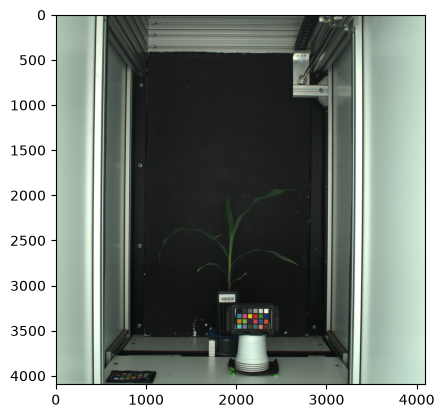

In [4]:
# Read in your image, which is based on the path you put above. For multispectral (MS) images, you can direct to a folder or to one image, and the other images in that folder will come along. 

ms = pcv.multispec.read_ms(os.path.dirname(args.image1))

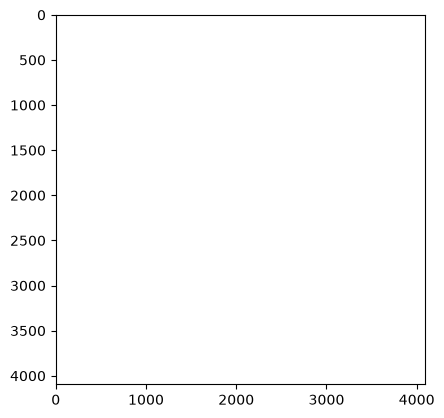

In [5]:
chl_img = pcv.multispec.read_ms(os.path.dirname(args.image1), pattern = 'MS455_((SV|TV))_BP650_(\\d+).*')

In [6]:
#gfp_img = pcv.multispec.read_ms(os.path.dirname(args.image1), pattern = 'MS475_((SV|TV))_BP520_(\\d+).*')

## Step 5: Explore the Multispectral Image

Before masking, take a look at what's inside your MS image: how many wavelength bands it has, which wavelengths they are, and what a single band looks like.

In [7]:
# evaluate the size of the images and how many bands are in the multispectral image (final number)
# shape is (rows, columns, number_of_wavelength_bands)
# @ignore
ms.array_data.shape

(4096, 4096, 11)

In [8]:
# evaluate which wavelengths are in the multispectral image
# keys are wavelengths (nm) available in this MS image; values are their index/order in ms.array_data
# @ignore
ms.wavelength_dict

{385: 0,
 410: 1,
 455: 2,
 475: 3,
 500: 4,
 525: 5,
 590: 6,
 660: 7,
 745: 8,
 850: 9,
 625: 10}

In [9]:
# As an example, let's look at just one wavelength. We need to call one that we know is in there, from the above list. 
# isolate just the 850 nm image from the multispectral image and plot it
# @ignore
ms850_img = ms.select(wavelength=850, ms=False)  # ms=False returns a plain image array instead of another MS_data object

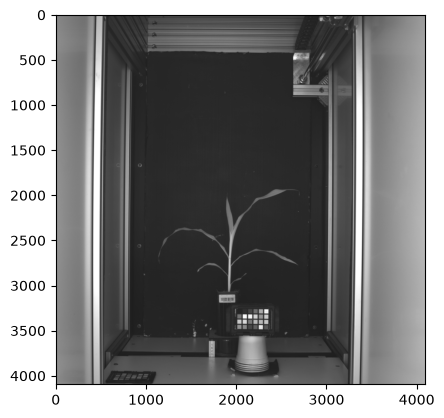

In [10]:
# @ignore
pcv.plot_image(ms850_img)

## Step 6: Choose a Masking Strategy

Explore colorspaces to find a channel that best separates the plant from the background, then threshold and clean up that channel to build a binary mask.

Note that this experiment has a special consideration for thresholding. Not all days will have all the same wavelengths present. Only `625` and `850` are present in each day. That leads to some odd workflows that we'll demonstrate in addition to the more normal `pseudo_rgb` based option.

In [ ]:
# Look at the colorspace - which of these looks the best for masking? Which channel makes the plant look most distinct?
# You can use individual wavelengths, the CHL image, or the pseudo-RGB image to evaluate the colorspace. 
# Here is an example using pseudo-RGB, which is a combination of three wavelengths (R=850, G=680, B=550) that is generated by PlantCV. 
# This is useful for learning, but because not all days of MS imaging have those wavelengths, you cannot make a single mask for all MS analysis.
# @ignore

colorspace_img = pcv.visualize.colorspaces(rgb_img=ms.pseudo_rgb())


In [ ]:
# Convert the pseudo-RGB image to grayscale using the a channel, which has good separation in plant from everything else 

# gray_img = pcv.rgb2gray_lab(rgb_img=ms.pseudo_rgb, channel='a')
# @ignore
gray_img = pcv.rgb2gray_cmyk(rgb_img=ms.pseudo_rgb(), channel='y')


In [ ]:
# Threshold the grayscale image to make a binary (black/white) mask
# object_type='dark' keeps pixels darker than the threshold value (the plant is dark in the 'a' channel here)
#thresh_a = pcv.threshold.binary(gray_img=gray_img, threshold=110, object_type='dark')
# @ignore
thresh_c = pcv.threshold.binary(gray_img=gray_img, threshold=70, object_type='light')

In [ ]:
# Fill in small holes/noise in the binary mask (removes objects smaller than 50 pixels)
# @ignore
c_fill_image = pcv.fill(bin_img=thresh_c, size=50)

In [ ]:
# Now let's try thresholding on the CHL image, which is present every time we take MS images, so will be consistent for our workflow. 
# @ignore
thresh_chl = pcv.threshold.binary(gray_img=chl_img.array_data, threshold=70, object_type='light')

# We are picking up a lot of other reflectance from the metal, we will filter this in a later step. 

In [ ]:
# @ignore
# Fill in small holes/noise in the binary mask (removes objects smaller than 50 pixels)
chl_fill_image = pcv.fill(bin_img=thresh_chl, size=50)

## Step 6.5: Thresholding on 625 and 850

Because we don't always have the same wavelengths present it might not work to threshold on the CHL image or on the pseudo-rgb if the wavelengths behind it change. One option is to make a new pseudo-rgb from what we do know will always be present.

In [11]:
import numpy as np
ex = np.stack([ms.select(625, False),
               ms.select(850, False),
               25 * np.ones(ms.select(625, False).shape)], axis=-1
             ).astype(np.uint8).squeeze()

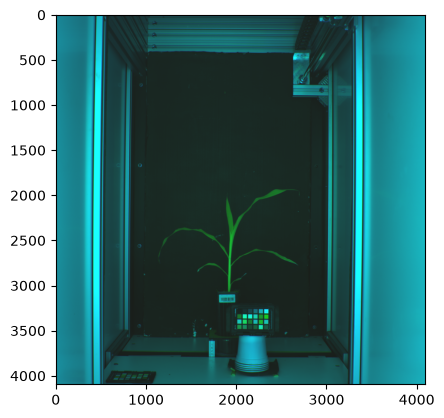

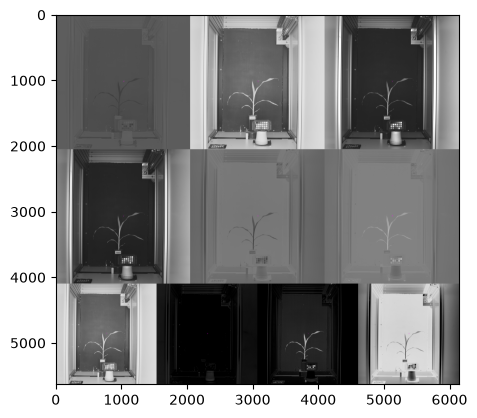

In [12]:
# @ignore
_ = pcv.plot_image(ex)
ex_colorspace_img = pcv.visualize.colorspaces(rgb_img=ex, original_img=False)

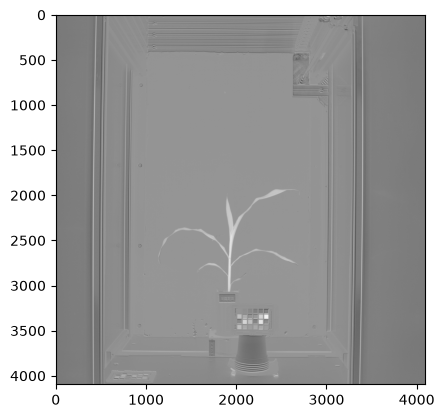

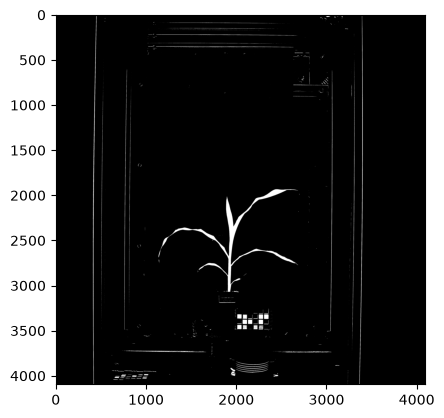

In [13]:
ex_b = pcv.rgb2gray_lab(ex, "b")
ex_b_thresh = pcv.threshold.binary(gray_img=ex_b, threshold=140, object_type='light')

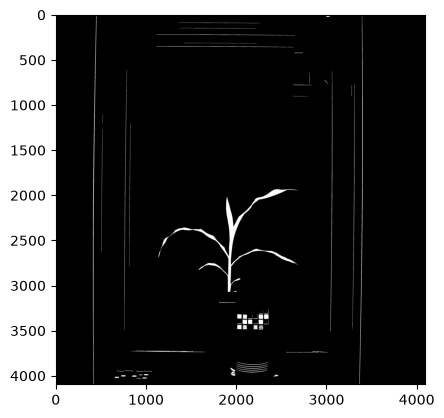

In [14]:
ex_fill_image = pcv.fill(bin_img=ex_b_thresh, size=200)

## Step 7: Define Your Region of Interest and Filter the Mask

Draw a box around where you expect your plant to be, then keep only the parts of your mask that fall inside it.

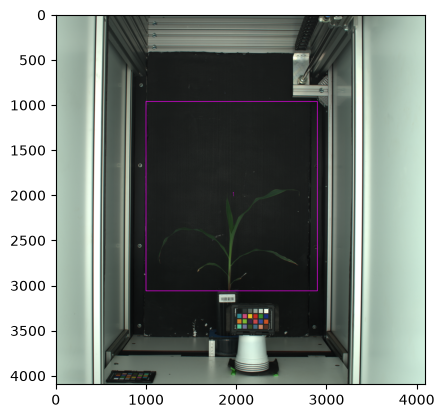

In [15]:
# Define the region of interest (ROI). This should include your plant, but not you color card or other things. 

# Inputs: 
#   img - RGB or grayscale image to plot the ROI on 
#   x - The x-coordinate of the upper left corner of the rectangle 
#   y - The y-coordinate of the upper left corner of the rectangle 
#   h - The height of the rectangle 
#   w - The width of the rectangle 

roi1 = pcv.roi.rectangle(img=ms.pseudo_rgb(), x=1000, y=960, h=2100, w=1900)

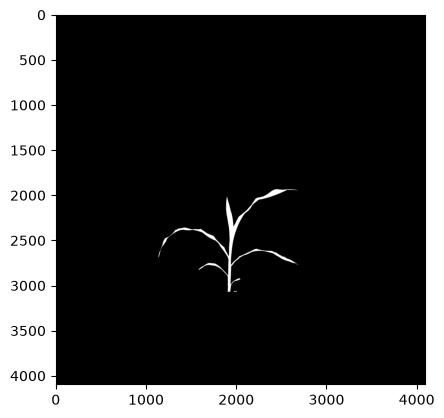

In [16]:
# Make a new filtered mask that only keeps the plant in your ROI and not objects outside of the ROI
# We have set to partial here so that if a leaf extends outside of your ROI it will still be selected. Switch to "cutto" if you have other plants that are getting selected on accident

# Inputs:
#    mask            = the clean mask you made above
#    roi            = the region of interest you specified above
#    roi_type       = 'partial' (default, for partially inside the ROI), 'cutto', or 
#                     'largest' (keep only largest contour)

kept_mask  = pcv.roi.quick_filter(mask=ex_fill_image, roi=roi1, roi_type='partial')


In [17]:
# we cover the label, not really a problem with the 2 channel image we hacked together.
kept_mask[3100:3200, 1817:2000] = 0

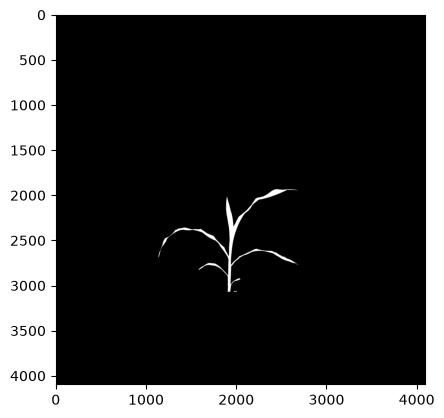

In [18]:
# @ignore
pcv.plot_image(kept_mask)

## Step 8: Chlorophyll Analysis

The chlorophyll image uses MS 455 nm and a bandpass filter of 650 nm to isolate just chlorophyll fluorescence. This image has to be imported separately from the MS stack, since it has a bandpass filter. 

alt.FacetChart(...)

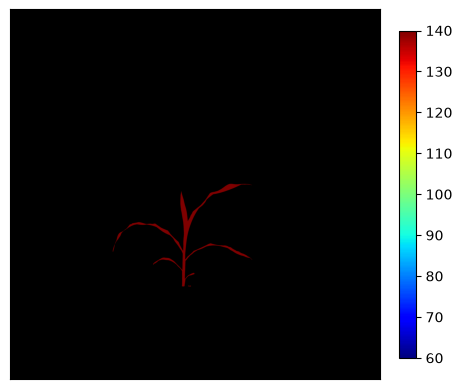

In [19]:
# Use the mask to analyze the CHL image. This will give you a histogram of the pixel values in the CHL image. 
# n_labels=1 means we're treating the whole masked area as one plant/object

_ = pcv.analyze.grayscale(gray_img=chl_img.array_data, labeled_mask=kept_mask, n_labels=1, bins=100)
_ = pcv.visualize.pseudocolor(gray_img = chl_img.array_data.squeeze(), mask=kept_mask, cmap='jet', 
                                               min_value=60, max_value=140)

## Step 9: GFP Analysis

The chlorophyll image uses MS 475 nm and a bandpass filter of 520 nm to isolate just GFP fluorescence. This image has to be imported separately from the MS stack, since it has a bandpass filter. 

Note that you will still see some signal even with no GFP due to autofluorescence. It is important to always compare your results to a control plant with no GFP. 

In [20]:
# Use the mask to analyze the GFP image. This will give you a histogram of the pixel values in the GFP image. 
# n_labels=1 means we're treating the whole masked area as one plant/object
#_ = pcv.analyze.grayscale(gray_img=gfp_img.array_data, labeled_mask=kept_mask, n_labels=1, bins=100)

#_ = pcv.visualize.pseudocolor(gray_img = gfp_img.array_data.squeeze(), mask=kept_mask, cmap='jet', 
#                                           min_value=25, max_value=60)

## Step 10: Spectral Index Analysis

Calculate vegetation/pigment indices from the MS image bands, then analyze and visualize each one. Indices that can be calculated with the Bellwether multispectral camera are: 
- **NDVI** (Normalized Difference Vegetation Index) - general plant vigor/greenness
- **SR** (Simple Ratio) - another general vegetation index, ratio-based
- **PSND_chlb** (Pigment Specific Normalized Difference, chlorophyll b) - chlorophyll b content
- **PSSR_chlb** (Pigment Specific Simple Ratio, chlorophyll b) - chlorophyll b content, ratio-based
- **SAVI** (Soil Adjusted Vegetation Index) - vegetation index that reduces soil brightness influence
- **EVI** (Enhanced Vegetation Index) - vegetation index correcting for atmospheric/canopy background effects
- **GLI** (Green Leaf Index) - visible-bands-only vegetation index computed from the pseudo-RGB image
- **VARI** (Visible Atmospherically Resistant Index) - vegetation index using only visible wavelengths
- **VI_GREEN** (Vegetation Index Green) - vegetation index using the green and red bands
- **GDVI** (Green Difference Vegetation Index) - vegetation index using the difference between NIR and green bands
- **EGI** (Excess Green Index) - visible-bands-only vegetation index computed from the pseudo-RGB image
- **ARI** (Anthocyanin Reflectance Index) - anthocyanin content
- **MARI** (Modified Anthocyanin Reflectance Index) - anthocyanin content, adjusted for chlorophyll/NIR reflectance
- **CRI550** (Carotenoid Reflectance Index 550) - carotenoid content
- **CRI700** (Carotenoid Reflectance Index 700) - carotenoid content
- **SIPI** (Structure-Independent Pigment Index) - carotenoid-to-chlorophyll ratio
- **PSND_CHLA** (Pigment Specific Normalized Difference, chlorophyll a) - chlorophyll a content
- **PSSR_CHLA** (Pigment Specific Simple Ratio, chlorophyll a) - chlorophyll a content, ratio-based
- **PSND_CAR** (Pigment Specific Normalized Difference, carotenoids) - carotenoid content
- **PSSR_CAR** (Pigment Specific Simple Ratio, carotenoids) - carotenoid content, ratio-based
- **PSRI** (Plant Senescence Reflectance Index) - senescence/stress indicator
- **CI_REDEDGE** (Chlorophyll Index Red Edge) - chlorophyll content
- **NDCI** (Normalized Difference Chlorophyll Index) - chlorophyll content
- **RGRI** (Red/Green Ratio Index) - anthocyanin-to-chlorophyll ratio

This is far more indices than most projects need to calculate! We have highlighted just a few of the most relevant indices below. Use your biological questions and hypotheses to decide which indices to calculate. 

### Only calculate indices when the wavelengths are present

Each index needs specific wavelengths, and some imaging days have many wavelengths while others only have a few. Every index is listed once below with the wavelengths it needs, and the loop runs only the ones this image can support. An index is skipped (and listed as skipped) if any wavelength it needs has no band within `TOLERANCE` nm, instead of stopping the workflow or quietly using a far-away band.

To add or remove an index, add or delete its line in `INDICES`. To change its histogram or color range, edit its numbers.


In [21]:
# DISTANCE is the max gap (nm) allowed between a wavelength an index needs and the closest band in this image.
# If any needed wavelength has no band that close, the index is skipped. Lower it (e.g., 25) to be stricter.
DISTANCE = 55

# One line per index:
#   name: (PlantCV function, wavelengths needed (nm),
#          histogram min_bin, max_bin, color min_value, max_value)
#   Wavelengths needed come from the PlantCV spectral_index source code.
INDICES = {
    "ndvi":       (pcv.spectral_index.ndvi, [670, 800], -1, 1, -0.25, 1),
    "psri":       (pcv.spectral_index.psri, [500, 678, 750], -1, 1, -0.25, 1),
    "ci_rededge": (pcv.spectral_index.ci_rededge, [700, 800], -1, 1, -0.25, 1),
    "ari":        (pcv.spectral_index.ari, [550, 700], -1, 1, -0.2, 0.2),
}

Wavelengths in this image: [385.0, 410.0, 455.0, 475.0, 500.0, 525.0, 590.0, 625.0, 660.0, 745.0, 850.0]
Calculating ndvi


alt.FacetChart(...)

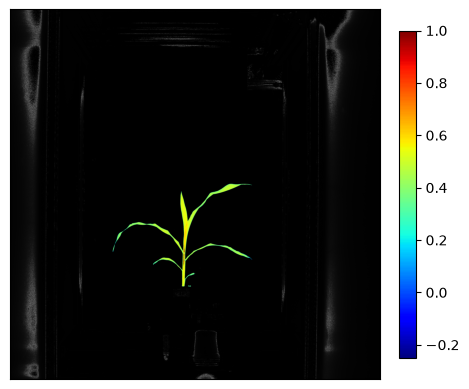

Calculating psri


alt.FacetChart(...)

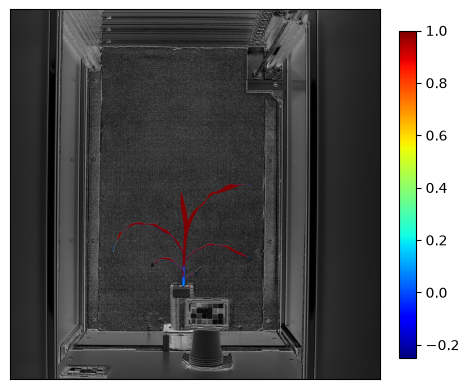

Calculating ci_rededge


alt.FacetChart(...)

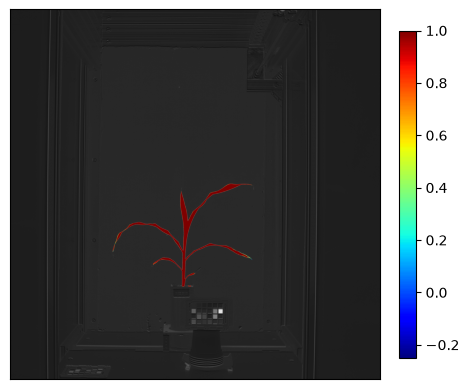

Calculating ari


alt.FacetChart(...)

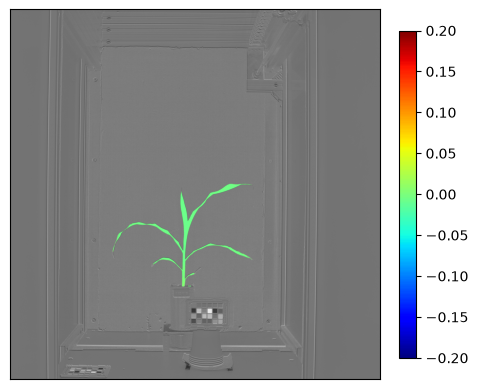

In [22]:
# Wavelengths (nm) available in this image
available = np.array([float(w) for w in ms.wavelength_dict.keys()])
print(f"Wavelengths in this image: {sorted(available.tolist())}")

for name, (func, needed, min_bin, max_bin, min_value, max_value) in INDICES.items():
    # Closest available band to each needed wavelength
    bands = [available[np.argmin(np.abs(available - wl))] for wl in needed]
    # Skip if a needed wavelength has no band within DISTANCE, or two needed wavelengths share one band
    if any(abs(b - wl) > DISTANCE for b, wl in zip(bands, needed)) or len(set(bands)) < len(bands):
        print(f"Skipping {name}: this image lacks separate bands near {needed} nm")
        continue

    # Workaround: PlantCV's debug preview of an MS index crashes on the 2-D index array
    debug = pcv.params.debug
    pcv.params.debug = None
    index_img = func(ms, distance=DISTANCE)
    pcv.params.debug = debug
    if index_img is None:  # PlantCV's own check can also decline (it warns and returns None)
        print(f"Skipping {name}: PlantCV could not calculate it with these wavelengths")
        continue

    print(f"Calculating {name}")
    # Workaround: spectral_index functions don't set array_type, but analyze.spectral_index needs it
    index_img.array_type = f"index_{name}"
    # Histogram of index values inside the plant mask (saved to the results file)
    pcv.analyze.spectral_index(index_img=index_img, labeled_mask=kept_mask,
                               min_bin=min_bin, max_bin=max_bin)
    # Pseudocolor image to see spatial patterns
    pcv.visualize.pseudocolor(gray_img=index_img.array_data, mask=kept_mask, cmap='jet',
                              min_value=min_value, max_value=max_value)

## Step 11: Shape Analysis

You can analyze shape either with the multispec image(s), or the RGB images. We will show analyze shape here to be thorough, but you do not need to do it on both image types, and we recommend using RGB instead because it will probably have more angles. 

In [ ]:
############### Shape Analysis ################ 
  
# Find shape properties, data gets stored to an Outputs class automatically

# Inputs:
#   img - RGB or grayscale image data 
#   labeled_mask - the mask of each individual object, set by the create_labels function. 
#   n_labels - the number of objects, set by the create_labels function. 

shape_image = pcv.analyze.size(img=ex, labeled_mask=kept_mask)


In [ ]:
# Shape properties relative to user boundary line (optional). This is useful if your plant is hanging below the pot and you want height from the top of the pot.
# Set your line_position by finding the x-value at the top of the pot, hover your cursor to get that value

# Inputs: 
#   img - RGB or grayscale image data 
#   obj - Single or grouped contour object 
#   mask - Binary mask of selected contours 
#   line_position - Position of boundary line (a value of 0 would draw a line 
#                   through the bottom of the image) 
#   label - Optional label parameter, modifies the variable name of observations recorded. (default `label="default"`)filled_img = pcv.morphology.fill_segments(mask=cropped_mask, objects=edge_objects)

shape_boundary_image = pcv.analyze.bound_horizontal(img=ex, labeled_mask=kept_mask, 
                                               line_position=3075)


## Step 12: Save Your Results

In [ ]:
# The save results function will take the measurements stored when running any PlantCV analysis functions, format, 
# and print an output text file for data analysis. The Outputs class stores data whenever any of the following functions
# are ran: analyze_bound_horizontal, analyze_bound_vertical, analyze_color, analyze_nir_intensity, analyze_object, 
# fluor_fvfm, report_size_marker_area, watershed. If no functions have been run, it will print an empty text file 

#This saves results for one image, and each image is saved individually if you run another image (it will overwrite the last one)
pcv.outputs.save_results(filename=args.result)

## Step 13: Build Your Batch Workflow

Congrats, you now know all the settings you like for this day of imaging! It's time to make this into a workflow so that it will analyze all your images at once and you can go have a cup of coffee. To do so, go back to the folder and open up the config_template.json file, and the config_workflow.py files, and you will edit them according to the values you changed in this file. 